<a href="https://colab.research.google.com/github/Siva-p-11/ML-assiments/blob/main/Hidden_Markov_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

np.random.seed(42)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset:", file_name)
print("Shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())


Saving smart_logistics_dataset.csv to smart_logistics_dataset.csv
Dataset: smart_logistics_dataset.csv
Shape: (1000, 16)

Available columns:
['Timestamp', 'Asset_ID', 'Latitude', 'Longitude', 'Inventory_Level', 'Shipment_Status', 'Temperature', 'Humidity', 'Traffic_Status', 'Waiting_Time', 'User_Transaction_Amount', 'User_Purchase_Frequency', 'Logistics_Delay_Reason', 'Asset_Utilization', 'Demand_Forecast', 'Logistics_Delay']


,Timestamp,Asset_ID,Latitude,Longitude,Inventory_Level,Shipment_Status,Temperature,Humidity,Traffic_Status,Waiting_Time,User_Transaction_Amount,User_Purchase_Frequency,Logistics_Delay_Reason,Asset_Utilization,Demand_Forecast,Logistics_Delay
0,2024-03-20 00:11:14,Truck_7,-65.7383,11.2497,390,Delayed,27.0,67.8,Detour,38,320,4,NaN,60.1,285,1
1,2024-10-30 07:53:51,Truck_6,22.2748,-131.7086,491,In Transit,22.5,54.3,Heavy,16,439,7,Weather,80.9,174,1
2,2024-07-29 18:42:48,Truck_10,54.9232,79.5455,190,In Transit,25.2,62.2,Detour,34,355,3,NaN,99.2,260,0
3,2024-10-28 00:50:54,Truck_9,42.3900,-1.4788,330,Delivered,25.4,52.3,Heavy,37,227,5,Traffic,97.4,160,1
4,2024-09-27 15:52:58,Truck_7,-65.8477,47.9468,480,Delayed,20.5,57.2,Clear,56,197,6,NaN,71.6,270,1


In [3]:

required = [
    "Timestamp", "Asset_ID", "Traffic_Status",
    "Waiting_Time", "Logistics_Delay"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)

df["Waiting_Time"] = pd.to_numeric(
    df["Waiting_Time"], errors="coerce"
)

df["Logistics_Delay"] = pd.to_numeric(
    df["Logistics_Delay"], errors="coerce"
)

df = df.dropna(subset=required).copy()
df = df.sort_values(["Asset_ID", "Timestamp"])

# Keep the notebook lightweight.
# Select up to 10 assets, with at least 10 observations each.
asset_counts = df["Asset_ID"].value_counts()
valid_assets = asset_counts[asset_counts >= 10].index[:10]

df = df[df["Asset_ID"].isin(valid_assets)].copy()

if len(df) < 10:
    raise ValueError(
        "Not enough sequential records. Check the uploaded CSV."
    )

# Map delay indicators to 0 or 1.
df["delay_flag"] = (
    df["Logistics_Delay"].astype(str).str.strip().str.lower()
    .map({
        "1": 1, "1.0": 1, "true": 1, "yes": 1,
        "0": 0, "0.0": 0, "false": 0, "no": 0
    })
)

# Handle alternative numeric encodings if necessary.
if df["delay_flag"].isna().any():
    numeric = pd.to_numeric(
        df["Logistics_Delay"], errors="coerce"
    )
    df["delay_flag"] = (numeric > 0).astype(int)

df["Traffic_Status"] = (
    df["Traffic_Status"].astype(str).str.lower().str.strip()
)

print("Prepared records:", len(df))
print("Assets:", df["Asset_ID"].nunique())

display(df[required].head(10))


Prepared records: 1000
Assets: 10


,Timestamp,Asset_ID,Traffic_Status,Waiting_Time,Logistics_Delay
610,2024-01-10 16:52:14,Truck_1,heavy,59,1
439,2024-01-10 20:02:28,Truck_1,heavy,48,1
788,2024-01-13 15:51:27,Truck_1,heavy,25,1
765,2024-01-13 21:07:39,Truck_1,clear,58,1
77,2024-01-15 12:01:25,Truck_1,clear,21,0
818,2024-01-17 04:29:26,Truck_1,clear,42,0
354,2024-01-18 17:13:48,Truck_1,clear,54,0
758,2024-01-20 21:06:05,Truck_1,heavy,16,1
615,2024-01-21 12:56:09,Truck_1,heavy,43,1
242,2024-01-21 13:17:03,Truck_1,detour,10,1


In [4]:

def classify_observation(row):
    delay = int(row["delay_flag"])
    waiting = row["Waiting_Time"]
    traffic = row["Traffic_Status"]

    # The categories are observed signals, not hidden states.
    heavy_traffic = any(
        word in traffic
        for word in ["heavy", "high", "severe", "congested"]
    )

    light_traffic = any(
        word in traffic
        for word in ["low", "light", "free"]
    )

    if delay == 1 and (heavy_traffic or waiting >= df["Waiting_Time"].median()):
        return "High_Risk"
    elif delay == 1 or heavy_traffic:
        return "Delayed"
    elif light_traffic and delay == 0:
        return "Normal"
    else:
        return "Moderate"

observation_names = ["Normal", "Moderate", "Delayed", "High_Risk"]
observation_to_id = {
    name: i for i, name in enumerate(observation_names)
}

df["Observation"] = df.apply(classify_observation, axis=1)
df["Observation_ID"] = df["Observation"].map(observation_to_id)

print("Observation distribution:")
display(df["Observation"].value_counts().to_frame("Count"))


Observation distribution:


,Count
Observation,
High_Risk,442
Moderate,434
Delayed,124


In [5]:

sequences = []

for asset_id, group in df.groupby("Asset_ID", sort=False):
    seq = group["Observation_ID"].to_numpy(dtype=int)

    if len(seq) > 0:
        sequences.append(seq)

print("Number of sequences:", len(sequences))
print("Total observations:", sum(len(s) for s in sequences))
print("Sequence lengths:", [len(s) for s in sequences])


Number of sequences: 10
Total observations: 1000
Sequence lengths: [89, 105, 105, 93, 107, 93, 103, 102, 109, 94]


In [6]:

N_STATES = 3
N_SYMBOLS = len(observation_names)

# Initial state distribution
pi = np.full(N_STATES, 1 / N_STATES)

# Transition probability matrix
A = np.full((N_STATES, N_STATES), 1 / N_STATES)

# Emission probability matrix
B = np.full((N_STATES, N_SYMBOLS), 1 / N_SYMBOLS)

print("Initial distribution pi:", pi)
print("\nInitial transition matrix A:\n", A)
print("\nInitial emission matrix B:\n", B)


Initial distribution pi: [0.33333333 0.33333333 0.33333333]

Initial transition matrix A:
 [[0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333]]

Initial emission matrix B:
 [[0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]]


In [7]:

def forward_backward(obs, pi, A, B):
    T = len(obs)
    N = len(pi)

    alpha = np.zeros((T, N))
    beta = np.zeros((T, N))
    scales = np.zeros(T)

    # Forward sum-product
    alpha[0] = pi * B[:, obs[0]]
    scales[0] = max(alpha[0].sum(), 1e-300)
    alpha[0] /= scales[0]

    for t in range(1, T):
        alpha[t] = (alpha[t-1] @ A) * B[:, obs[t]]
        scales[t] = max(alpha[t].sum(), 1e-300)
        alpha[t] /= scales[t]

    # Backward sum-product
    beta[-1] = 1.0

    for t in range(T-2, -1, -1):
        beta[t] = A @ (B[:, obs[t+1]] * beta[t+1])
        beta[t] /= scales[t+1]

    # Posterior probability of each hidden state
    gamma = alpha * beta
    gamma /= np.maximum(gamma.sum(axis=1, keepdims=True), 1e-300)

    log_likelihood = np.sum(np.log(scales))

    return alpha, beta, gamma, log_likelihood


In [8]:

def train_hmm(sequences, n_states=3, n_symbols=4, iterations=100):
    rng = np.random.default_rng(42)

    pi = np.full(n_states, 1 / n_states)
    A = rng.random((n_states, n_states)) + 0.5
    A /= A.sum(axis=1, keepdims=True)

    B = rng.random((n_states, n_symbols)) + 0.5
    B /= B.sum(axis=1, keepdims=True)

    eps = 1e-8
    likelihood_history = []

    for iteration in range(iterations):
        pi_sum = np.zeros(n_states)
        A_num = np.zeros((n_states, n_states))
        A_den = np.zeros(n_states)
        B_num = np.zeros((n_states, n_symbols))
        B_den = np.zeros(n_states)
        total_ll = 0.0

        for obs in sequences:
            alpha, beta, gamma, ll = forward_backward(obs, pi, A, B)
            total_ll += ll

            pi_sum += gamma[0]

            for t in range(len(obs)):
                B_num[:, obs[t]] += gamma[t]
                B_den += gamma[t]

            for t in range(len(obs) - 1):
                xi = (
                    alpha[t][:, None] * A
                    * (B[:, obs[t+1]] * beta[t+1])[None, :]
                )
                xi /= max(xi.sum(), eps)

                A_num += xi
                A_den += gamma[t]

        likelihood_history.append(total_ll)

        # M-step with small smoothing for numerical stability
        pi = pi_sum + eps
        pi /= pi.sum()

        A = A_num + eps
        A /= A.sum(axis=1, keepdims=True)

        B = B_num + eps
        B /= B.sum(axis=1, keepdims=True)

    return pi, A, B, likelihood_history


pi, A, B, likelihood_history = train_hmm(
    sequences,
    n_states=N_STATES,
    n_symbols=N_SYMBOLS,
    iterations=100
)

print("Training complete.")
print("Final log-likelihood:", likelihood_history[-1])


Training complete.
Final log-likelihood: -981.7002683963781


In [9]:

state_names = [
    "Smooth",
    "Moderate Delay",
    "Systemic Disruption"
]

# Give the states interpretable labels based on expected severity.
risk_weights = np.array([0, 1, 2, 3])
state_risk = B @ risk_weights

order = np.argsort(state_risk)
state_labels = [""] * N_STATES

for rank, state_id in enumerate(order):
    state_labels[state_id] = state_names[rank]

print("Initial state probabilities:")
display(pd.DataFrame({
    "State": state_labels,
    "Probability": pi
}))

print("Transition probabilities:")
display(pd.DataFrame(A, index=state_labels, columns=state_labels))

print("Emission probabilities:")
display(pd.DataFrame(
    B,
    index=state_labels,
    columns=observation_names
).round(3))


Initial state probabilities:


,State,Probability
0,Moderate Delay,0.350372
1,Systemic Disruption,0.645286
2,Smooth,0.004342


Transition probabilities:


,Moderate Delay,Systemic Disruption,Smooth
Moderate Delay,0.339898,0.243253,0.416849
Systemic Disruption,0.307147,0.165949,0.526905
Smooth,0.384197,0.381387,0.234415


Emission probabilities:


,Normal,Moderate,Delayed,High_Risk
Moderate Delay,0.0,0.367,0.165,0.469
Systemic Disruption,0.0,0.392,0.090,0.518
Smooth,0.0,0.527,0.112,0.361


In [10]:

def update_state_probability(previous_probability, observation_id, A, B):
    # Predict current state from previous state
    predicted = previous_probability @ A

    # Incorporate the newest observation
    posterior = predicted * B[:, observation_id]
    posterior /= max(posterior.sum(), 1e-300)

    return posterior


# Demonstration using the final observation in the first sequence
obs = sequences[0]
alpha, beta, gamma, ll = forward_backward(obs, pi, A, B)

current_probability = gamma[-1]

print("Latest observation:", observation_names[obs[-1]])
print("\nCurrent hidden-state probabilities:")

for i, label in enumerate(state_labels):
    print(f"{label}: {current_probability[i]:.2%}")

disruption_index = state_labels.index("Systemic Disruption")

print(
    "\nEstimated systemic disruption probability:",
    f"{current_probability[disruption_index]:.2%}"
)

# Example: process a new incoming observation
new_observation_id = obs[-1]

updated_probability = update_state_probability(
    current_probability, new_observation_id, A, B
)

print("\nUpdated probabilities after a new observation:")
for i, label in enumerate(state_labels):
    print(f"{label}: {updated_probability[i]:.2%}")


Latest observation: Moderate

Current hidden-state probabilities:
Moderate Delay: 29.80%
Systemic Disruption: 25.87%
Smooth: 44.33%

Estimated systemic disruption probability: 25.87%

Updated probabilities after a new observation:
Moderate Delay: 29.77%
Systemic Disruption: 25.82%
Smooth: 44.41%


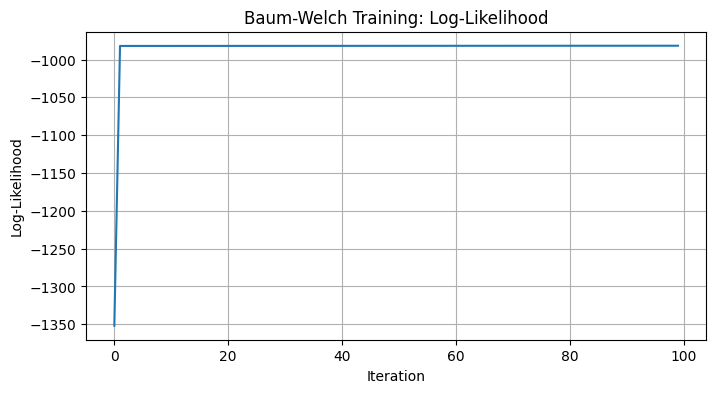

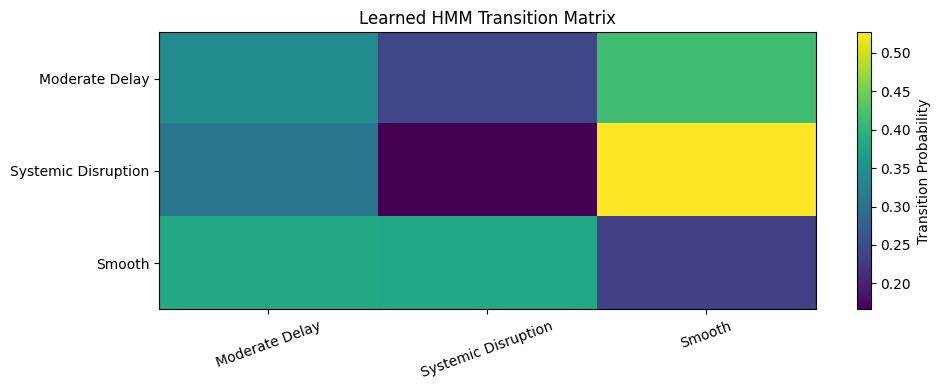

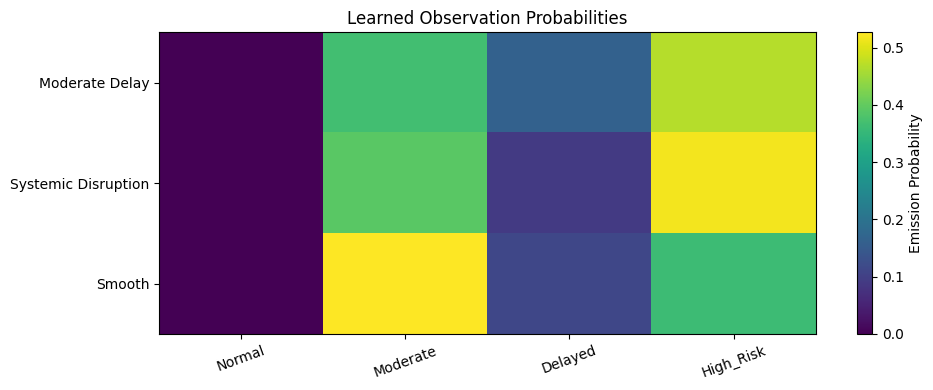

In [11]:

plt.figure(figsize=(8, 4))
plt.plot(likelihood_history)
plt.title("Baum-Welch Training: Log-Likelihood")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.imshow(A, aspect="auto")
plt.xticks(range(N_STATES), state_labels, rotation=20)
plt.yticks(range(N_STATES), state_labels)
plt.colorbar(label="Transition Probability")
plt.title("Learned HMM Transition Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.imshow(B, aspect="auto")
plt.xticks(range(N_SYMBOLS), observation_names, rotation=20)
plt.yticks(range(N_STATES), state_labels)
plt.colorbar(label="Emission Probability")
plt.title("Learned Observation Probabilities")
plt.tight_layout()
plt.show()


In [12]:

result_frames = []

for asset_id, group in df.groupby("Asset_ID", sort=False):
    obs = group["Observation_ID"].to_numpy(dtype=int)
    alpha, beta, gamma, ll = forward_backward(obs, pi, A, B)

    result = group[[
        "Timestamp", "Asset_ID", "Observation", "Waiting_Time",
        "Traffic_Status", "Logistics_Delay"
    ]].copy()

    for state_id, label in enumerate(state_labels):
        result[f"P_{label.replace(' ', '_')}"] = gamma[:, state_id]

    result["Most_Likely_State"] = [
        state_labels[i] for i in gamma.argmax(axis=1)
    ]

    result_frames.append(result)

results = pd.concat(result_frames, ignore_index=True)
results.to_csv("hmm_supply_chain_results.csv", index=False)

files.download("hmm_supply_chain_results.csv")

display(results.head(10))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Timestamp,Asset_ID,Observation,Waiting_Time,Traffic_Status,Logistics_Delay,P_Moderate_Delay,P_Systemic_Disruption,P_Smooth,Most_Likely_State
0,2024-01-10 16:52:14,Truck_1,High_Risk,59,heavy,1,0.334965,0.661676,0.003359,Systemic Disruption
1,2024-01-10 20:02:28,Truck_1,High_Risk,48,heavy,1,0.346386,0.225299,0.428315,Smooth
2,2024-01-13 15:51:27,Truck_1,High_Risk,25,heavy,1,0.368011,0.313642,0.318346,Moderate Delay
3,2024-01-13 21:07:39,Truck_1,High_Risk,58,clear,1,0.368242,0.316932,0.314825,Moderate Delay
4,2024-01-15 12:01:25,Truck_1,Moderate,21,clear,0,0.293304,0.247259,0.459436,Smooth
5,2024-01-17 04:29:26,Truck_1,Moderate,42,clear,0,0.306040,0.280570,0.413390,Smooth
6,2024-01-18 17:13:48,Truck_1,Moderate,54,clear,0,0.293214,0.246563,0.460223,Smooth
7,2024-01-20 21:06:05,Truck_1,High_Risk,16,heavy,1,0.368889,0.319213,0.311898,Moderate Delay
8,2024-01-21 12:56:09,Truck_1,High_Risk,43,heavy,1,0.365895,0.303849,0.330256,Moderate Delay
9,2024-01-21 13:17:03,Truck_1,Delayed,10,detour,1,0.461114,0.197756,0.341130,Moderate Delay
